In [1]:
import datetime
import netCDF4
import scipy
import numpy as np
import importlib
import SICEBaselineScroller
import matplotlib.pyplot as plt
importlib.reload(SICEBaselineScroller)

<module 'SICEBaselineScroller' from '/mnt/c/Users/user/Desktop/rnd/AISat/VolumeInversion/torched/SICEBaselineScroller.py'>

In [2]:
scroller = SICEBaselineScroller.SICEBaselineScroller(start=20070101, end=20070201, season=None)

In [3]:
import skimage
mask = scroller.monthly_mask(datetime.datetime(2007,1,1),0.5,1,0,1e-5)

generating filter mask for:  2007-01-01 00:00:00


### POINT PROCESSING : POISSON DISK SAMPLER

(1336, 12000)

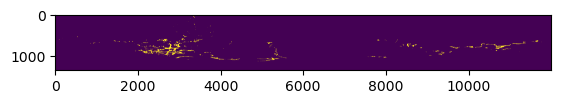

In [5]:
plt.imshow(mask)
mask.shape

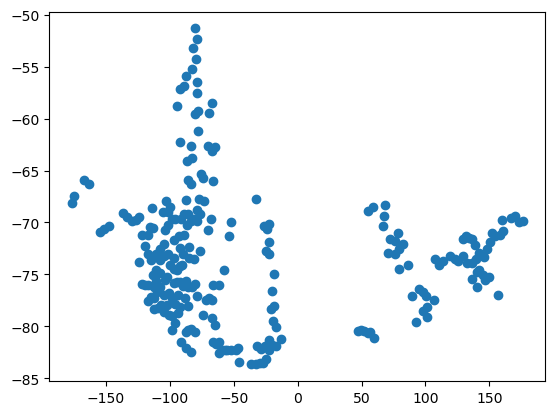

In [105]:
#loc_valids = np.stack(np.where(mask), axis=-1)
llg_valids = scroller.llgrid[:, mask].transpose()
v_inds = np.arange(llg_valids.shape[0])
v_mask = np.ones(v_inds.size, dtype=bool)

llsep = np.array((1, 2))[None, :]
points = []
while(v_mask.any()):
    pt = np.random.choice(v_inds[v_mask])
    v_mask[(np.abs(llg_valids - llg_valids[pt]) < llsep).all(axis=-1)] = 0
    points.append(llg_valids[pt])
points = np.array(points)
plt.scatter(points[:,1], -points[:,0])

In [110]:
[f'POINT({pt[1]} {pt[0]})' for pt in np.round(points,4)]

['POINT(-114.84 73.59)',
 'POINT(-96.57 71.7)',
 'POINT(140.7 76.17)',
 'POINT(-104.49 76.95)',
 'POINT(-109.86 76.68)',
 'POINT(-96.93 75.84)',
 'POINT(158.4 71.16)',
 'POINT(86.07 74.13)',
 'POINT(-115.35 70.44)',
 'POINT(-92.46 75.69)',
 'POINT(110.85 74.1)',
 'POINT(-92.13 72.42)',
 'POINT(-87.69 75.66)',
 'POINT(60.0 81.12)',
 'POINT(-32.01 81.93)',
 'POINT(145.8 73.32)',
 'POINT(-17.31 81.93)',
 'POINT(-29.49 83.52)',
 'POINT(-102.66 67.98)',
 'POINT(-76.23 69.21)',
 'POINT(-114.75 77.13)',
 'POINT(-24.87 83.13)',
 'POINT(-99.69 68.55)',
 'POINT(-69.48 77.31)',
 'POINT(101.52 78.09)',
 'POINT(-24.15 70.59)',
 'POINT(79.08 72.54)',
 'POINT(-93.84 78.72)',
 'POINT(-87.66 80.58)',
 'POINT(-78.63 69.9)',
 'POINT(170.4 69.42)',
 'POINT(-20.49 78.3)',
 'POINT(-119.37 72.27)',
 'POINT(129.3 73.26)',
 'POINT(-63.72 81.66)',
 'POINT(-78.81 68.76)',
 'POINT(129.54 71.58)',
 'POINT(-83.52 69.87)',
 'POINT(-82.89 76.17)',
 'POINT(166.83 69.57)',
 'POINT(97.8 76.65)',
 'POINT(-83.52 80.25)',


## Point Processing: Line connection attempt

In [98]:
# assess connection (distance & validity of halfway point)
dists = ((points[None,:,:] - points[:,None,:])**2).sum(axis=-1)
tmp = ((points[None,:,:] + points[:,None,:]) // 2).reshape((points.shape[0]**2, 2))
dists[~mask[tmp[:,0],tmp[:,1]].reshape(dists.shape)] = 0
dists = np.triu(dists)

# number of valid connections divided by their respective distances - if this is near zero, it's not worth it!
weights = ((dists > 0)/(dists+1)).sum(axis=1)

print (weights.max())

0.0014165872884661392


### POLYGON PREPROCESSING : INTERIOR HOLE REMOVAL

In [246]:
mask = tmp_mask.copy(); mask[0, :] = mask[-1, :] = False; mask[:, 0] = mask[:, -1] = False;
tmp = scipy.signal.convolve2d(mask, np.ones((3,3)))[1:-1,1:-1] < 4 #find disconnected pixels
mask[tmp] = 0
distance = scipy.ndimage.distance_transform_edt(mask)#plt.imshow(distance)

inv_distance = scipy.ndimage.distance_transform_edt(~mask)
impassable = inv_distance > 3
base_seed = ~(inv_distance > 2) * ~mask

cost = scipy.ndimage.gaussian_filter(distance, 1)
cost[impassable] = np.max(cost) * 2#cost[impassable] = -1

labels = scipy.ndimage.label(~mask) #separate invalid regions (holes)

In [268]:
slate = np.zeros_like(mask)
unlinked = list(range(labels[1]))
for i in range(labels[1]):
    #print("checking label:", i)
    seedi = np.array(np.where(base_seed * (labels[0] == i)))
    if (seedi.size < 1): continue
    for j in unlinked:
        if (i==j): continue
        seedj = np.array(np.where(base_seed * (labels[0] == j)))
        if (seedj.size < 1): continue
        pi12 = np.array((np.random.choice(np.arange(seedi[0].size)),
                         np.random.choice(np.arange(seedj[0].size))))
        try:
            path = np.array(skimage.graph.route_through_array(cost, seedi[:,pi12[0]],seedj[:,pi12[1]])[0])
            slate[path[:, 0], path[:, 1]] = 1
            unlinked.remove(j)
        except: continue

mask2 = mask.copy()
mask2[scipy.ndimage.maximum_filter(slate, size=(3,3))] = 0

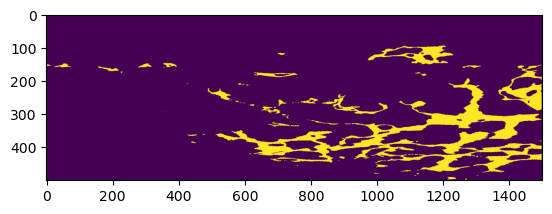

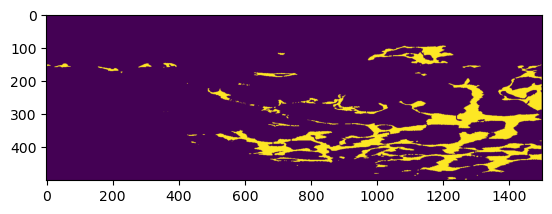

In [270]:
plt.imshow(mask); plt.show()
plt.imshow(mask2[:,:])#; plt.colorbar()